In [1]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import root_mean_squared_error
from xgboost import XGBRegressor

In [3]:
from urllib.request import urlretrieve

data_path = Path("data/yellow_tripdata_2026-05.parquet")
data_path.parent.mkdir(exist_ok=True)

url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-05.parquet"

if not data_path.exists():
    urlretrieve(url, data_path)

print("Fichier disponible :", data_path)

Fichier disponible : data/yellow_tripdata_2026-05.parquet


In [5]:
data_path = Path("data/yellow_tripdata_2026-05.parquet")

if not data_path.exists():
    raise FileNotFoundError(f"Fichier introuvable : {data_path}")

data_path

PosixPath('data/yellow_tripdata_2026-05.parquet')

In [6]:
df = pd.read_parquet(data_path)
df.shape

(4090836, 20)

In [7]:
columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance",
]

df = pd.read_parquet(data_path, columns=columns)
df.shape

(4090836, 5)

In [8]:
df["duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["duration"].describe()

count    4.090836e+06
mean     1.877588e+01
std      2.671057e+01
min      0.000000e+00
25%      8.583333e+00
50%      1.448333e+01
75%      2.326667e+01
max      9.960150e+03
Name: duration, dtype: float64

In [9]:
df = df[df["duration"].between(1, 60)].copy()

categorical = ["PULocationID", "DOLocationID"]
numerical = ["trip_distance"]

df[categorical] = df[categorical].astype(str)
df["PU_DO"] = df["PULocationID"] + "_" + df["DOLocationID"]

df.shape

(3883752, 7)

In [10]:
sample_size = min(200_000, len(df))
df = df.sample(n=sample_size, random_state=42)
df = df.sort_values("tpep_pickup_datetime").reset_index(drop=True)

df.shape

(200000, 7)

In [11]:
split_index = int(len(df) * 0.8)

df_train = df.iloc[:split_index].copy()
df_val = df.iloc[split_index:].copy()

len(df_train), len(df_val)

(160000, 40000)

In [12]:
features = ["PU_DO", "trip_distance"]

train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")

dv = DictVectorizer()
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

y_train = df_train["duration"].to_numpy()
y_val = df_val["duration"].to_numpy()

X_train.shape, X_val.shape

((160000, 12641), (40000, 12641))

In [13]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_val)
linear_rmse = root_mean_squared_error(y_val, linear_predictions)

linear_rmse

6.652815344851184

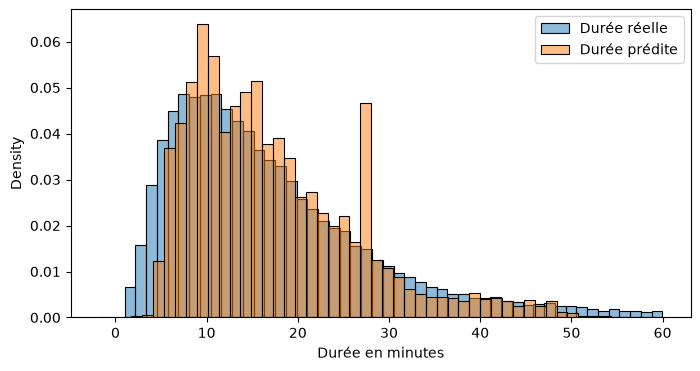

In [14]:
plt.figure(figsize=(8, 4))
sns.histplot(y_val, label="Durée réelle", stat="density", bins=50, alpha=0.5)
sns.histplot(
    linear_predictions,
    label="Durée prédite",
    stat="density",
    bins=50,
    alpha=0.5,
)
plt.xlabel("Durée en minutes")
plt.legend()
plt.show()

In [16]:
import numpy as np

X_train_lasso = X_train.tocsc(copy=True)

assert max(X_train_lasso.shape) < np.iinfo(np.int32).max
assert X_train_lasso.nnz < np.iinfo(np.int32).max

X_train_lasso.indices = X_train_lasso.indices.astype(np.int32)
X_train_lasso.indptr = X_train_lasso.indptr.astype(np.int32)

In [19]:
lasso_model = Lasso(alpha=0.01, max_iter=10_000)
lasso_model.fit(X_train_lasso, y_train)

lasso_predictions = lasso_model.predict(X_val)
lasso_rmse = root_mean_squared_error(y_val, lasso_predictions)

lasso_rmse

10.517043400486218

In [20]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)
xgb_rmse = root_mean_squared_error(y_val, xgb_predictions)

xgb_rmse

6.471618951707119

In [21]:
results = pd.DataFrame(
    {
        "model": ["LinearRegression", "Lasso", "XGBoost"],
        "rmse": [linear_rmse, lasso_rmse, xgb_rmse],
    }
).sort_values("rmse")

results

,model,rmse
2,XGBoost,6.471619
0,LinearRegression,6.652815
1,Lasso,10.517043


In [22]:
models = {
    "LinearRegression": (linear_model, linear_rmse),
    "Lasso": (lasso_model, lasso_rmse),
    "XGBoost": (xgb_model, xgb_rmse),
}

selected_name = min(models, key=lambda name: models[name][1])
selected_model, selected_rmse = models[selected_name]

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
model_path = models_dir / "duration_model.bin"

with model_path.open("wb") as output_file:
    pickle.dump((dv, selected_model), output_file)

selected_name, selected_rmse, model_path

('XGBoost', 6.471618951707119, PosixPath('models/duration_model.bin'))

In [23]:
with model_path.open("rb") as input_file:
    loaded_dv, loaded_model = pickle.load(input_file)

example = [{"PU_DO": "161_236", "trip_distance": 3.2}]
example_matrix = loaded_dv.transform(example)
prediction = loaded_model.predict(example_matrix)[0]

prediction

np.float32(21.65231)

In [24]:
lasso_trials = []

for alpha in [0.001, 0.1]:
    model = Lasso(alpha=alpha, max_iter=10_000)
    model.fit(X_train_lasso, y_train)

    predictions = model.predict(X_val)
    rmse = root_mean_squared_error(y_val, predictions)

    lasso_trials.append({
        "alpha": alpha,
        "rmse": rmse,
    })

pd.DataFrame(lasso_trials)

,alpha,rmse
0,0.001,7.877294
1,0.100,10.977719


In [25]:
xgb_trial = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

xgb_trial.fit(X_train, y_train)

xgb_trial_predictions = xgb_trial.predict(X_val)
xgb_trial_rmse = root_mean_squared_error(y_val, xgb_trial_predictions)

xgb_trial_rmse

6.429282944505554

### Comparaison et choix du modèle

| Modèle | Paramètre testé | RMSE de validation (minutes) |
|---|---|---:|
| Régression linéaire | Paramètres par défaut | 6,6528 |
| Lasso | alpha = 0,001 | 7,8773 |
| Lasso | alpha = 0,01 | 10,5170 |
| Lasso | alpha = 0,1 | 10,9777 |
| XGBoost | 100 arbres | 6,4716 |
| XGBoost | 200 arbres | 6,4293 |

Je retiens XGBoost avec 200 arbres, car il obtient la plus faible
RMSE sur le même jeu de validation. Le gain par rapport à 100 arbres
reste limité. Ces résultats concernent ce jeu de validation et ne
garantissent pas les mêmes performances sur de nouvelles données.

### Informations à conserver pour reproduire les essais

- La source et la version du fichier de données : Yellow Taxi, mai 2026.
- Les règles de préparation : durée en minutes, filtre entre 1 et
  60 minutes, création de PU_DO.
- L'échantillon de 200 000 trajets avec random_state = 42.
- Le tri chronologique et la séparation entraînement/validation à 80/20.
- Les variables utilisées et le DictVectorizer entraîné.
- Les paramètres de chaque modèle et les RMSE obtenues.
- Le code, sa version Git et les versions de Python et des bibliothèques.
- Les adaptations de compatibilité, notamment les indices int32 pour Lasso.

In [26]:
selected_name = "XGBoost — 200 arbres"
selected_model = xgb_trial
selected_rmse = xgb_trial_rmse

with model_path.open("wb") as output_file:
    pickle.dump((dv, selected_model), output_file)

with model_path.open("rb") as input_file:
    loaded_dv, loaded_model = pickle.load(input_file)

example = [{"PU_DO": "161_236", "trip_distance": 3.2}]
prediction = loaded_model.predict(
    loaded_dv.transform(example)
)[0]

print("Modèle retenu :", selected_name)
print("RMSE de validation :", selected_rmse)
print("Nombre d'arbres :", loaded_model.get_params()["n_estimators"])
print("Durée prédite en minutes :", prediction)

Modèle retenu : XGBoost — 200 arbres
RMSE de validation : 6.429282944505554
Nombre d'arbres : 200
Durée prédite en minutes : 21.624043
